# 04 — Model × Technique Benchmark

**Goal:** the full grid — 4 models × 4 imbalance techniques = 16 experiments, each scored with 5-fold stratified CV on the training set.

| Models | Techniques |
|---|---|
| Logistic Regression (linear baseline) | None |
| Random Forest (bagging) | Class weights |
| XGBoost (boosting) | Undersampling (1:1) |
| LightGBM (boosting) | SMOTE (fraud → 10% of legit) |

"Class weights" means each library's own mechanism: `class_weight='balanced'` for LogReg, `'balanced_subsample'` for RF, `scale_pos_weight = n_legit / n_fraud` for XGBoost / LightGBM.

⏱ **Runtime:** roughly 15–40 minutes on a laptop — Random Forest is the slow part. Set `RUN_MODELS` below to a smaller list while experimenting.

In [1]:
import sys
sys.path.append("..")   # so `src` is importable from notebooks/

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)

import json, time

from src.config import REPORTS_DIR, FIGURES_DIR
from src.utils import load_splits, make_experiment, cv_evaluate, MODEL_NAMES, TECHNIQUES

X_train, X_test, y_train, y_test = load_splits()   # test set still untouched
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Train: {len(y_train):,} rows | frauds: {y_train.sum()} | pos_weight = {pos_weight:.0f}")

Train: 226,980 rows | frauds: 378 | pos_weight = 599


In [2]:
RUN_MODELS = MODEL_NAMES          # e.g. ["LogReg", "XGBoost"] for a quick run
RUN_TECHNIQUES = TECHNIQUES

## 1. Run the grid

In [3]:
rows = []
start = time.time()
for model_name in RUN_MODELS:
    for technique in RUN_TECHNIQUES:
        t0 = time.time()
        pipe = make_experiment(model_name, technique, pos_weight=pos_weight)
        res = cv_evaluate(pipe, X_train, y_train)
        res.update(model=model_name, technique=technique)
        rows.append(res)
        print(f"{model_name:<13} | {technique:<14} | PR-AUC {res['pr_auc']:.4f} "
              f"| P {res['precision']:.3f} R {res['recall']:.3f} | {time.time() - t0:.0f}s")
print(f"\nTotal: {(time.time() - start) / 60:.1f} min")

grid = pd.DataFrame(rows).set_index(["model", "technique"])
grid.to_csv(REPORTS_DIR / "04_benchmark_results.csv")

LogReg        | None           | PR-AUC 0.7527 | P 0.868 R 0.614 | 4s


LogReg        | Class weights  | PR-AUC 0.7544 | P 0.060 R 0.918 | 7s


LogReg        | Undersampling  | PR-AUC 0.6024 | P 0.044 R 0.913 | 1s


LogReg        | SMOTE          | PR-AUC 0.7556 | P 0.403 R 0.865 | 6s


RandomForest  | None           | PR-AUC 0.8370 | P 0.939 R 0.772 | 339s


RandomForest  | Class weights  | PR-AUC 0.8382 | P 0.933 R 0.765 | 187s


... (6 outputs left out)

LightGBM      | None           | PR-AUC 0.6024 | P 0.413 R 0.653 | 25s


LightGBM      | Class weights  | PR-AUC 0.5138 | P 0.038 R 0.769 | 14s


LightGBM      | Undersampling  | PR-AUC 0.7268 | P 0.059 R 0.905 | 7s


LightGBM      | SMOTE          | PR-AUC 0.8535 | P 0.870 R 0.831 | 31s

Total: 16.8 min


## 2. Results table (sorted by PR-AUC)

In [4]:
cols = ["pr_auc", "pr_auc_std", "roc_auc", "precision", "recall", "f1", "fit_time_s"]
grid[cols].sort_values("pr_auc", ascending=False).style.background_gradient(
    subset=["pr_auc", "precision", "recall", "f1"], cmap="Greens"
).format("{:.4f}")

## 3. Heatmaps: PR-AUC, precision and recall per combination

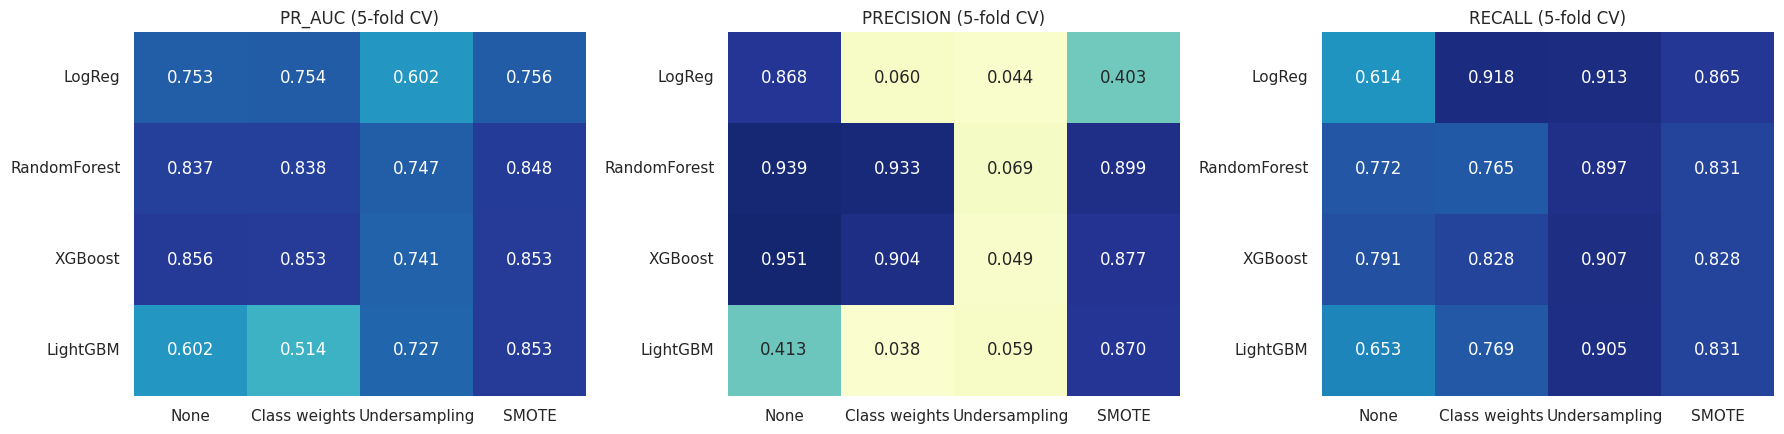

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, metric in zip(axes, ["pr_auc", "precision", "recall"]):
    pivot = grid[metric].unstack("technique").reindex(index=RUN_MODELS, columns=RUN_TECHNIQUES)
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0, vmax=1, ax=ax, cbar=False)
    ax.set_title(metric.upper() + " (5-fold CV)")
    ax.set_xlabel(""); ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_benchmark_heatmaps.png", dpi=120, bbox_inches="tight")
plt.show()

### What to look for

1. **Rows (models):** do the tree ensembles beat LogReg on PR-AUC? On this dataset they usually do — fraud patterns are non-linear combinations of the V-features, which a linear model can't capture.
2. **Columns (techniques):** for the boosted models, does any technique beat "None" on PR-AUC? Often it doesn't — strong models already rank fraud well; resampling mainly shifts the precision/recall balance.
3. **Undersampling column:** recall high, precision very low for most models — training on ~600 rows discards too much legit information.
4. **pr_auc_std:** with only ~380 frauds in training, fold-to-fold noise is real. Two configs within about one std of each other are effectively tied — don't over-claim a winner.

## 4. Pick the winner

In [6]:
best_idx = grid["pr_auc"].idxmax()
best = grid.loc[best_idx]
print(f"Best by PR-AUC: {best_idx[0]} + {best_idx[1]}")
print(best[["pr_auc", "pr_auc_std", "precision", "recall", "f1"]])

# Configs statistically tied with the winner (within 1 std)
tied = grid[grid["pr_auc"] >= best["pr_auc"] - best["pr_auc_std"]].sort_values("pr_auc", ascending=False)
print("\nWithin 1 std of the best:")
print(tied[["pr_auc", "pr_auc_std", "fit_time_s"]])

Best by PR-AUC: XGBoost + None
pr_auc       0.8560
pr_auc_std   0.0340
precision    0.9513
recall       0.7909
f1           0.8622
Name: (XGBoost, None), dtype: float64

Within 1 std of the best:
                            pr_auc  pr_auc_std  fit_time_s
model        technique                                    
XGBoost      None           0.8560      0.0340      3.6878
LightGBM     SMOTE          0.8535      0.0273      5.0217
XGBoost      SMOTE          0.8531      0.0336      4.4207
             Class weights  0.8529      0.0311      3.9631
RandomForest SMOTE          0.8479      0.0332     63.2760
             Class weights  0.8382      0.0317     37.0651
             None           0.8370      0.0360     67.4595


In [7]:
best_config = {"model": best_idx[0], "technique": best_idx[1],
               "cv_pr_auc": float(best["pr_auc"]), "cv_pr_auc_std": float(best["pr_auc_std"])}
with open(REPORTS_DIR / "04_best_config.json", "w") as f:
    json.dump(best_config, f, indent=2)
best_config

{'model': 'XGBoost',
 'technique': 'None',
 'cv_pr_auc': 0.855963358682866,
 'cv_pr_auc_std': 0.03395235690305251}

The winner is chosen **only** from cross-validation on the training set. If a simpler/faster config is tied (see the table above), it's a perfectly defensible choice to override `best_config` with it — just write down why.

Next: `05_threshold` tunes the decision threshold for this config and finally touches the test set.